**Enhancement Citra Menggunakan Low Pass Filter (LPF) dalam Domain Frekuensi**

---

### 1. Konsep Low Pass Filter (LPF)

Low Pass Filter dalam domain frekuensi digunakan untuk menyaring frekuensi tinggi pada citra, sehingga detail halus dan noise dikurangi. Frekuensi rendah yang berisi informasi dasar citra tetap dipertahankan.

**Manfaat LPF**:
- Menghaluskan citra (smoothing)
- Mengurangi noise
- Mengurangi detail kecil

Penerapannya dilakukan dengan mengalikan spektrum frekuensi dari citra dengan filter frekuensi rendah, lalu dilakukan inverse Fourier transform untuk mendapatkan citra hasil.

---

### 2. Jenis-Jenis LPF dan Rumus

#### a. Ideal Low Pass Filter (ILPF)
Filter berbentuk disk (lingkaran) di domain frekuensi.
$$ H(u,v) = \begin{cases}1, & \text{jika } D(u,v) \leq D_0 \\ 0, & \text{jika } D(u,v) > D_0 \end{cases} $$

#### b. Butterworth Low Pass Filter (BLPF)
Filter dengan transisi halus antara daerah pass dan stop band.
$$ H(u,v) = \frac{1}{1 + (\frac{D(u,v)}{D_0})^{2n}} $$

#### c. Gaussian Low Pass Filter (GLPF)
Transisi paling mulus, tanpa osilasi.
$$ H(u,v) = e^{-\frac{D^2(u,v)}{2D_0^2}} $$

Dimana:
- \[ D(u,v) \]: Jarak Euclidean dari pusat frekuensi
- \[ Do \]: Frekuensi cutoff
- \[ n \]: Order dari Butterworth

---

### 3. Implementasi Python

#### a. Template Fungsi Filter
```python
import numpy as np

def create_distance_matrix(shape):
    M, N = shape
    u = np.arange(M)
    v = np.arange(N)
    U, V = np.meshgrid(v, u)
    D = np.sqrt((U - N//2)**2 + (V - M//2)**2)
    return D
```

#### b. Ideal LPF
```python
def ideal_lpf(shape, D0):
    D = create_distance_matrix(shape)
    H = np.zeros_like(D)
    H[D <= D0] = 1
    return H
```

#### c. Butterworth LPF
```python
def butterworth_lpf(shape, D0, n):
    D = create_distance_matrix(shape)
    H = 1 / (1 + (D / D0)**(2 * n))
    return H
```

#### d. Gaussian LPF
```python
def gaussian_lpf(shape, D0):
    D = create_distance_matrix(shape)
    H = np.exp(-(D**2) / (2 * (D0**2)))
    return H
```

---

### 4. Aplikasi ke Citra dan Visualisasi
```python
import cv2
import matplotlib.pyplot as plt

# Load citra grayscale
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
F = np.fft.fft2(img)
F_shift = np.fft.fftshift(F)

# Terapkan filter
D0 = 30
H = gaussian_lpf(img.shape, D0)
G_shift = F_shift * H

# Invers FFT
G = np.fft.ifftshift(G_shift)
img_filtered = np.abs(np.fft.ifft2(G))

# Visualisasi Filter dan Magnitudo
plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1), plt.imshow(img, cmap='gray')
plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(np.log(1 + np.abs(F_shift)), cmap='gray')
plt.title('Spektrum Asli'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(H, cmap='gray')
plt.title('Spektrum Filter (Gaussian)'), plt.axis('off')
plt.show()

# Tampilkan hasil
plt.figure()
plt.imshow(img_filtered, cmap='gray')
plt.title('Hasil LPF (Gaussian)'), plt.axis('off')
plt.show()
```

---

### 5. Eksperimen Parameterisasi

Eksperimen ini bertujuan membandingkan efek berbagai parameter terhadap hasil filtering.

#### a. Pengaruh D0 terhadap Gaussian LPF
```python
for D0 in [10, 30, 60]:
    H = gaussian_lpf(img.shape, D0)
    G_shift = F_shift * H
    G = np.fft.ifftshift(G_shift)
    img_filtered = np.abs(np.fft.ifft2(G))

    plt.figure(figsize=(6, 3))
    plt.imshow(img_filtered, cmap='gray')
    plt.title(f'Gaussian LPF (D0={D0})')
    plt.axis('off')
    plt.show()
```

#### b. Pengaruh Orde n pada Butterworth LPF
```python
for n in [1, 2, 4]:
    H = butterworth_lpf(img.shape, 30, n)
    G_shift = F_shift * H
    G = np.fft.ifftshift(G_shift)
    img_filtered = np.abs(np.fft.ifft2(G))

    plt.figure(figsize=(6, 3))
    plt.imshow(img_filtered, cmap='gray')
    plt.title(f'Butterworth LPF (n={n})')
    plt.axis('off')
    plt.show()
```

---

### 6. Perbandingan Visual dan Analisis

Eksperimen perbandingan antara ILPF, BLPF, dan GLPF dengan parameter \( Do \) yang sama dapat menunjukkan perbedaan hasil smoothing. Semakin tinggi \( Do \), semakin banyak frekuensi yang dipertahankan.

Kita dapat membandingkan hasilnya secara kuantitatif menggunakan MSE atau PSNR terhadap citra asli (terutama jika citra referensi tanpa noise tersedia).

```python
from skimage.metrics import peak_signal_noise_ratio as psnr

ref = img  # citra referensi
psnr_val = psnr(ref, img_filtered)
print("PSNR:", psnr_val)
```

---

### 7. Kesimpulan

Penggunaan Low Pass Filter dalam domain frekuensi memungkinkan penghilangan komponen frekuensi tinggi yang umumnya mengandung noise atau detail halus. Tiga jenis filter yang umum digunakan—Ideal, Butterworth, dan Gaussian—memiliki karakteristik yang berbeda terkait transisi dari passband ke stopband. Gaussian memberikan hasil paling halus, sementara Ideal memiliki batasan keras yang bisa menghasilkan ringing. Dengan melakukan eksperimen pada parameter seperti cutoff frequency \( Do \) dan orde filter, pengguna dapat menyesuaikan efek smoothing sesuai kebutuhan. Visualisasi spektrum filter membantu memahami bagaimana filter bekerja, dan evaluasi kuantitatif seperti PSNR bisa digunakan untuk menilai efektivitas transformasi.


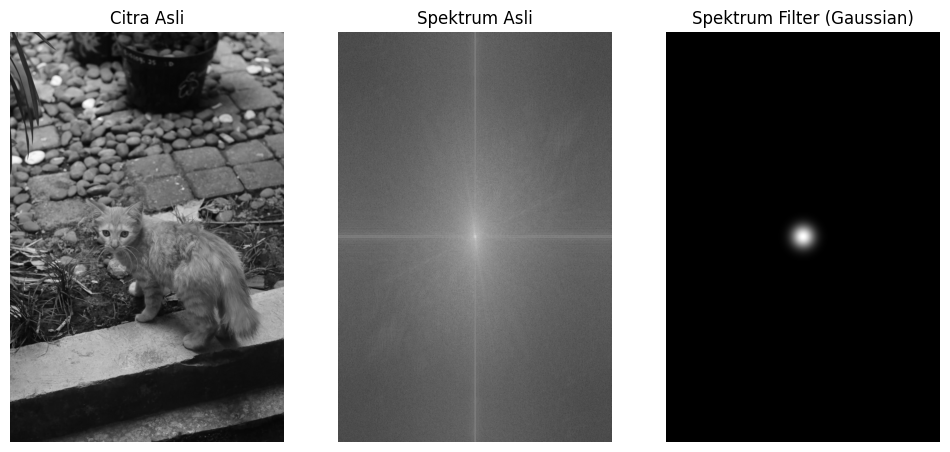

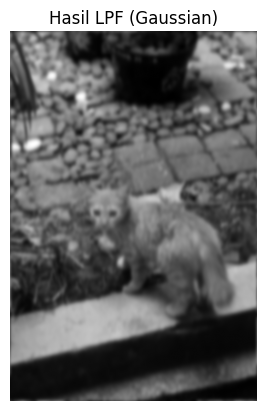

5.a Pengaruh Cutoff Frequency (D0) terhadap Gaussian LPF


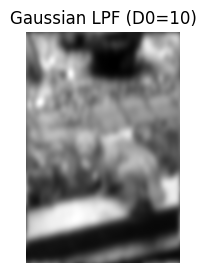

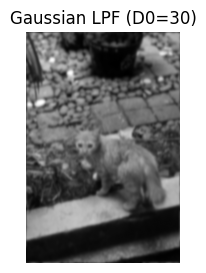

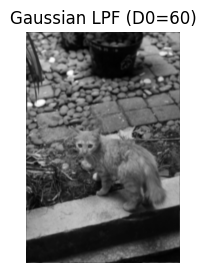

5.b Pengaruh Orde (n) pada Butterworth LPF (D0=30)


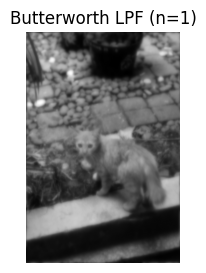

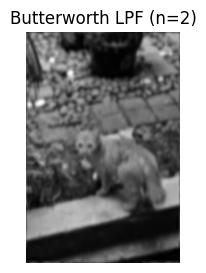

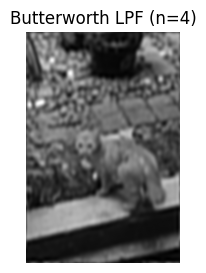

6. Perbandingan Visual Antara ILPF, BLPF, dan GLPF (D0=30)


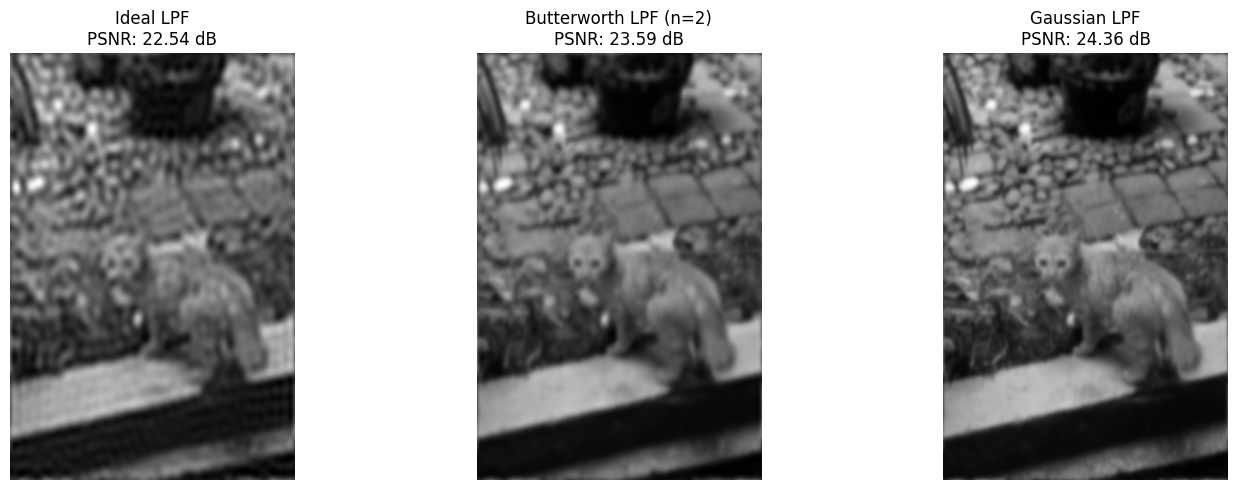

PSNR (Gaussian LPF D0=30 vs Asli): 24.3647 dB

--- Ringkasan Evaluasi PSNR ---
PSNR Ideal LPF: 22.5383 dB
PSNR Butterworth LPF (n=2): 23.5933 dB
PSNR Gaussian LPF: 24.3647 dB


In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr

def create_distance_matrix(shape):
    M, N = shape
    u = np.arange(M)
    v = np.arange(N)
    U, V = np.meshgrid(v, u)
    D = np.sqrt((U - N // 2) ** 2 + (V - M // 2) ** 2)
    return D

# b. Ideal LPF
def ideal_lpf(shape, D0):
    D = create_distance_matrix(shape)
    H = np.zeros_like(D)
    H[D <= D0] = 1
    return H

# c. Butterworth LPF
def butterworth_lpf(shape, D0, n):
    D = create_distance_matrix(shape)
    H = 1 / (1 + (D / D0) ** (2 * n))
    return H

# d. Gaussian LPF
def gaussian_lpf(shape, D0):
    D = create_distance_matrix(shape)
    H = np.exp(-(D ** 2) / (2 * (D0 ** 2)))
    return H

def apply_lpf(img, H):
    F = np.fft.fft2(img)
    F_shift = np.fft.fftshift(F)      
    G_shift = F_shift * H             
    G = np.fft.ifftshift(G_shift)     
    img_back = np.abs(np.fft.ifft2(G))
    return np.clip(img_back, 0, 255).astype(np.uint8)

img_path = 'image.jpg'
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"Citra '{img_path}' tidak ditemukan!")

F = np.fft.fft2(img)
F_shift = np.fft.fftshift(F)

D0 = 30
H = gaussian_lpf(img.shape, D0)
G_shift = F_shift * H

G = np.fft.ifftshift(G_shift)
img_filtered = np.abs(np.fft.ifft2(G))

plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_shift)), cmap='gray')
plt.title('Spektrum Asli')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(H, cmap='gray')
plt.title('Spektrum Filter (Gaussian)')
plt.axis('off')
plt.show()

plt.figure()
plt.imshow(img_filtered, cmap='gray')
plt.title('Hasil LPF (Gaussian)')
plt.axis('off')
plt.show()

print("5.a Pengaruh Cutoff Frequency (D0) terhadap Gaussian LPF")
for D0 in [10, 30, 60]:
    H = gaussian_lpf(img.shape, D0)
    G_shift = F_shift * H
    G = np.fft.ifftshift(G_shift)
    img_filtered_d0 = np.abs(np.fft.ifft2(G))

    plt.figure(figsize=(6, 3))
    plt.imshow(img_filtered_d0, cmap='gray')
    plt.title(f'Gaussian LPF (D0={D0})')
    plt.axis('off')
    plt.show()

# b. Pengaruh Orde n pada Butterworth LPF
print("5.b Pengaruh Orde (n) pada Butterworth LPF (D0=30)")
for n in [1, 2, 4]:
    H = butterworth_lpf(img.shape, 30, n)
    G_shift = F_shift * H
    G = np.fft.ifftshift(G_shift)
    img_filtered_n = np.abs(np.fft.ifft2(G))

    plt.figure(figsize=(6, 3))
    plt.imshow(img_filtered_n, cmap='gray')
    plt.title(f'Butterworth LPF (n={n})')
    plt.axis('off')
    plt.show()

print("6. Perbandingan Visual Antara ILPF, BLPF, dan GLPF (D0=30)")
D0_comp = 30
H_ilpf = ideal_lpf(img.shape, D0_comp)
H_blpf = butterworth_lpf(img.shape, D0_comp, n=2)
H_glpf = gaussian_lpf(img.shape, D0_comp)

filter_dict = {
    'Ideal LPF': H_ilpf,
    'Butterworth LPF (n=2)': H_blpf,
    'Gaussian LPF': H_glpf
}

plt.figure(figsize=(15, 5))

results = {}

for idx, (name, H_f) in enumerate(filter_dict.items(), 1):
    G_s = F_shift * H_f
    g_res = np.abs(np.fft.ifft2(np.fft.ifftshift(G_s)))
    results[name] = g_res
    val_psnr = psnr(img, g_res, data_range=255)
    
    plt.subplot(1, 3, idx)
    plt.imshow(g_res, cmap='gray')
    plt.title(f"{name}\nPSNR: {val_psnr:.2f} dB")
    plt.axis('off')

plt.tight_layout()
plt.show()

ref = img  # citra referensi
psnr_val = psnr(ref, img_filtered, data_range=255)
print(f"PSNR (Gaussian LPF D0=30 vs Asli): {psnr_val:.4f} dB")

print("\n--- Ringkasan Evaluasi PSNR ---")
for name, res_img in results.items():
    score = psnr(ref, res_img, data_range=255)
    print(f"PSNR {name}: {score:.4f} dB")


1. Eksperimen ILPF vs BLPF (D0 = 30 dan 100) & Perbandingan PSNR
D0 =  30 | PSNR ILPF:  22.53 dB | PSNR BLPF (n=2):  23.59 dB


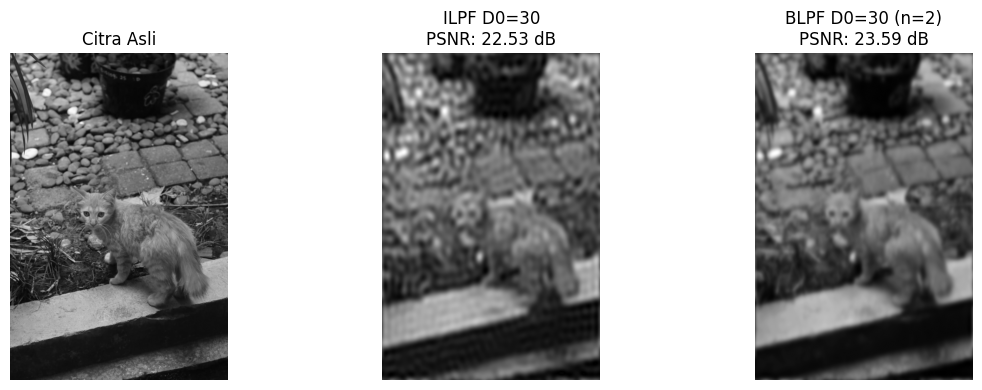

D0 = 100 | PSNR ILPF:  30.14 dB | PSNR BLPF (n=2):  31.29 dB


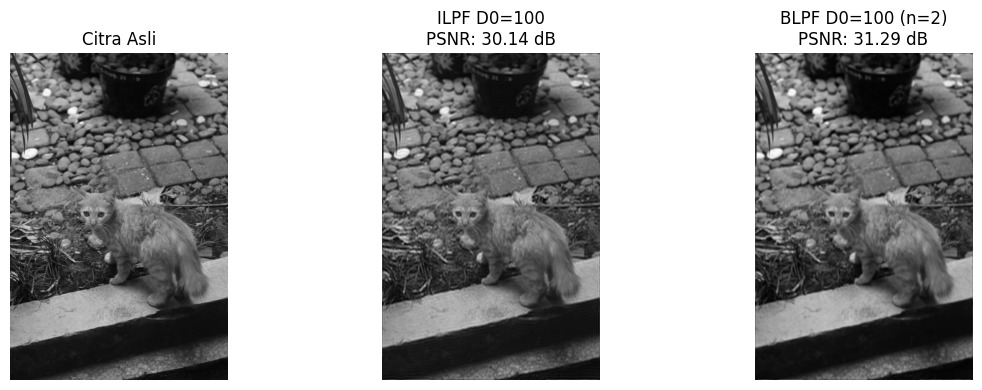

2. Eksperimen Butterworth LPF vs ILPF dengan Variasi Orde n (D0 = 30)
Orde n = 1 | PSNR ILPF: 22.53 dB | PSNR BLPF: 24.22 dB
Orde n = 2 | PSNR ILPF: 22.53 dB | PSNR BLPF: 23.59 dB
Orde n = 3 | PSNR ILPF: 22.53 dB | PSNR BLPF: 23.28 dB
Orde n = 4 | PSNR ILPF: 22.53 dB | PSNR BLPF: 23.11 dB


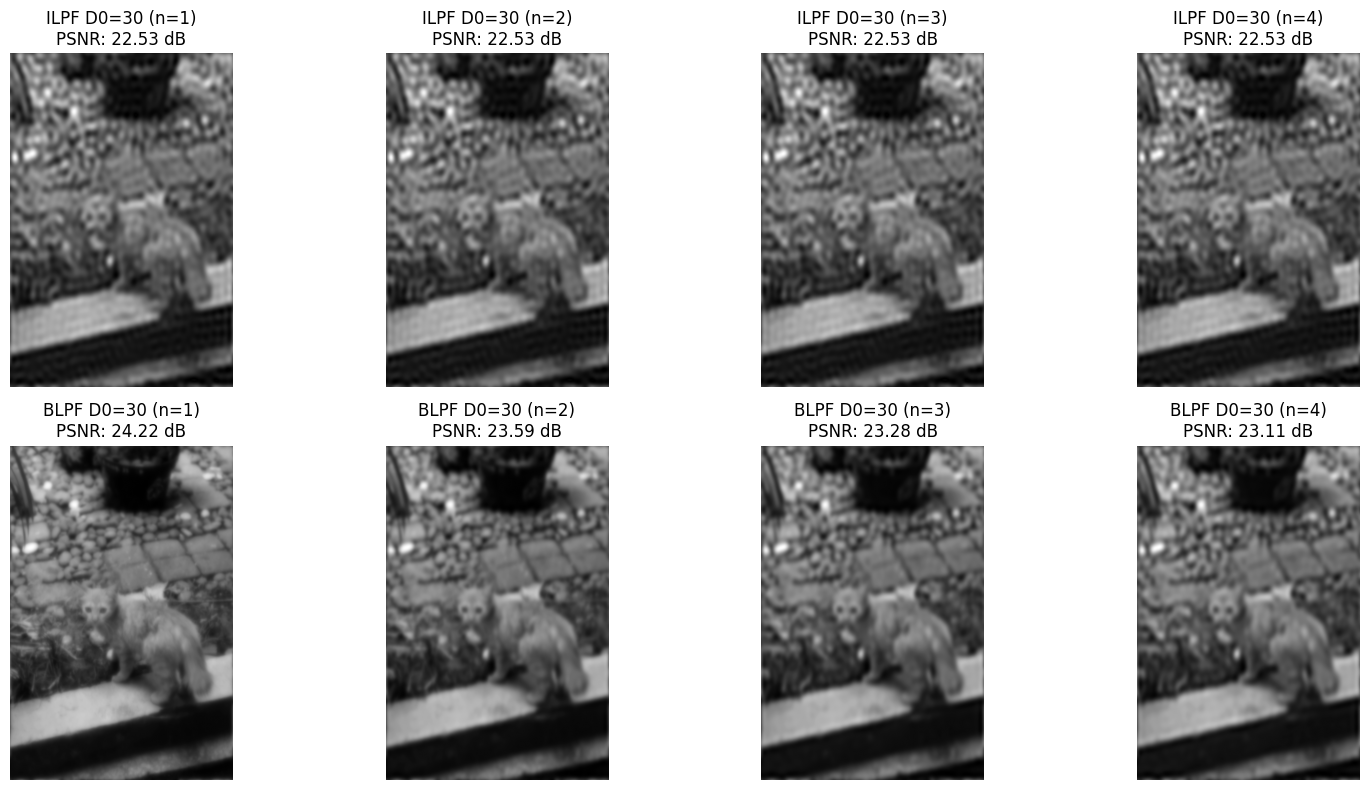

3. Pembanding Semua Metode LPF (ILPF, BLPF, GLPF) dengan D0 = 50
PSNR ILPF      (D0=50)     : 25.29 dB
PSNR BLPF n=2  (D0=50)     : 26.42 dB
PSNR GLPF      (D0=50)     : 27.28 dB


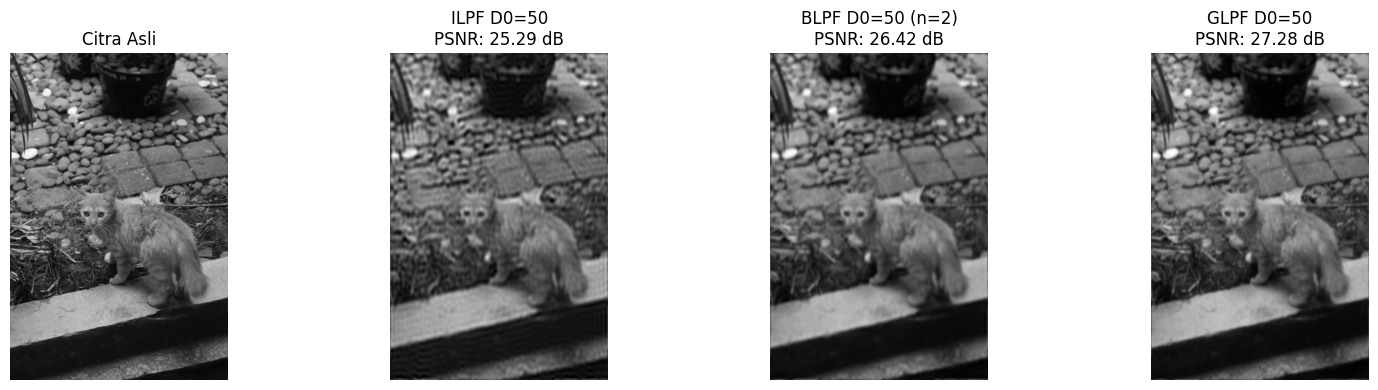

In [3]:
print("1. Eksperimen ILPF vs BLPF (D0 = 30 dan 100) & Perbandingan PSNR")

for D0 in [30, 100]:
    H_ilpf = ideal_lpf(img.shape, D0)
    H_blpf = butterworth_lpf(img.shape, D0, n=2)
    
    img_ilpf = apply_lpf(img, H_ilpf)
    img_blpf = apply_lpf(img, H_blpf)
    
    psnr_ilpf = psnr(img, img_ilpf)
    psnr_blpf = psnr(img, img_blpf)
    
    print(f"D0 = {D0:3d} | PSNR ILPF: {psnr_ilpf:6.2f} dB | PSNR BLPF (n=2): {psnr_blpf:6.2f} dB")
    
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title('Citra Asli')
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(img_ilpf, cmap='gray')
    plt.title(f'ILPF D0={D0}\nPSNR: {psnr_ilpf:.2f} dB')
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    plt.imshow(img_blpf, cmap='gray')
    plt.title(f'BLPF D0={D0} (n=2)\nPSNR: {psnr_blpf:.2f} dB')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

print("2. Eksperimen Butterworth LPF vs ILPF dengan Variasi Orde n (D0 = 30)")

D0_fixed = 30
H_ilpf_30 = ideal_lpf(img.shape, D0_fixed)
img_ilpf_30 = apply_lpf(img, H_ilpf_30)
psnr_ilpf_30 = psnr(img, img_ilpf_30)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx, n in enumerate([1, 2, 3, 4]):
    H_blpf_n = butterworth_lpf(img.shape, D0_fixed, n)
    img_blpf_n = apply_lpf(img, H_blpf_n)
    psnr_blpf_n = psnr(img, img_blpf_n)
    
    print(f"Orde n = {n} | PSNR ILPF: {psnr_ilpf_30:.2f} dB | PSNR BLPF: {psnr_blpf_n:.2f} dB")
    
    axes[0, idx].imshow(img_ilpf_30, cmap='gray')
    axes[0, idx].set_title(f'ILPF D0=30 (n={n})\nPSNR: {psnr_ilpf_30:.2f} dB')
    axes[0, idx].axis('off')
    
    axes[1, idx].imshow(img_blpf_n, cmap='gray')
    axes[1, idx].set_title(f'BLPF D0=30 (n={n})\nPSNR: {psnr_blpf_n:.2f} dB')
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()


print("3. Pembanding Semua Metode LPF (ILPF, BLPF, GLPF) dengan D0 = 50")

D0_comp = 50
H_i = ideal_lpf(img.shape, D0_comp)
H_b = butterworth_lpf(img.shape, D0_comp, n=2)
H_g = gaussian_lpf(img.shape, D0_comp)

img_i = apply_lpf(img, H_i)
img_b = apply_lpf(img, H_b)
img_g = apply_lpf(img, H_g)

psnr_i = psnr(img, img_i)
psnr_b = psnr(img, img_b)
psnr_g = psnr(img, img_g)

print(f"PSNR ILPF      (D0=50)     : {psnr_i:.2f} dB")
print(f"PSNR BLPF n=2  (D0=50)     : {psnr_b:.2f} dB")
print(f"PSNR GLPF      (D0=50)     : {psnr_g:.2f} dB")

plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(img_i, cmap='gray')
plt.title(f'ILPF D0=50\nPSNR: {psnr_i:.2f} dB')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(img_b, cmap='gray')
plt.title(f'BLPF D0=50 (n=2)\nPSNR: {psnr_b:.2f} dB')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(img_g, cmap='gray')
plt.title(f'GLPF D0=50\nPSNR: {psnr_g:.2f} dB')
plt.axis('off')

plt.tight_layout()
plt.show()